In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lifelines import KaplanMeierFitter
from matplotlib.patheffects import withStroke

In [2]:
# ---
# Configuration
# ---

file_path = "data/combined_dataset.xlsx"
sheet_names = [
    "Gas - 85",
    "Gas - 90",
    "Gas - 95",
]

technology_col = "Technology"
capacity_col = "Capacity (MW)"
lifespan_col = "Lifespan"
event_col = "Event"

REFERENCE_LEVELS = [
    0.8,
    0.5,
    0.1,
]


# ---
# Style
# ---

FONT_BASE = 12.0
FONT_TICKS = 12.0
FONT_TITLE = 12.5
FONT_PANEL = 12.5
FONT_REFERENCE_LABEL = 12.0
FONT_INFO = 12.0
FONT_AXIS_LABEL = 13.5

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.75,
        "axes.labelsize": FONT_AXIS_LABEL,
        "axes.titlesize": FONT_TITLE,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TICKS,
        "legend.fontsize": 12.0,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)

KM_COLOUR = "#1D5A7A"
CI_COLOUR = "#DEDBD5"
REFERENCE_COLOUR = "#134257"
REFERENCE_LABEL_COLOUR = "#134257"
GRID_COLOUR = "#C9C9C9"

TEXT_COLOUR = "#1A1A1A"
SECONDARY_TEXT_COLOUR = "#4A4A4A"
AXIS_COLOUR = "#4A4A4A"
COLOR_BACKGROUND = "white"


def halo(linewidth=2.4, foreground="white"):
    return [
        withStroke(
            linewidth=linewidth,
            foreground=foreground,
        )
    ]

In [3]:
# ---
# Load and prepare sensitivity datasets
# ---

workbook = pd.ExcelFile(
    file_path
)

missing_sheets = [
    sheet
    for sheet in sheet_names
    if sheet not in workbook.sheet_names
]

if missing_sheets:
    raise ValueError(
        "Missing expected sheet(s): "
        + ", ".join(missing_sheets)
    )


def prepare_sheet(sheet_name):
    """
    Load one sensitivity sheet and apply the same filters
    used in the reference survival-curve notebook.
    """

    df = pd.read_excel(
        file_path,
        sheet_name=sheet_name,
    )

    required_columns = [
        lifespan_col,
        event_col,
        capacity_col,
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"Sheet '{sheet_name}' is missing column(s): "
            + ", ".join(missing_columns)
        )

    df_km = df.copy()

    for column in [
        lifespan_col,
        event_col,
        capacity_col,
    ]:
        df_km[column] = pd.to_numeric(
            df_km[column],
            errors="coerce",
        )

    drop_columns = [
        lifespan_col,
        event_col,
    ]

    if technology_col in df_km.columns:
        drop_columns.insert(
            0,
            technology_col,
        )

    df_km = df_km.dropna(
        subset=drop_columns
    ).copy()

    # Preserve the original analysis condition.
    df_km = df_km[
        (df_km[lifespan_col] > 0)
        & (df_km[capacity_col] > 0)
    ].copy()

    # The workbook is expected to contain Natural Gas sensitivity
    # datasets. If Technology is present, retain Natural Gas only.
    if technology_col in df_km.columns:
        df_km = df_km[
            df_km[technology_col] == "Natural Gas"
        ].copy()

    if df_km.empty:
        raise ValueError(
            f"No valid Natural Gas observations remain in "
            f"sheet '{sheet_name}' after filtering."
        )

    return df_km


sensitivity_data = {
    sheet: prepare_sheet(
        sheet
    )
    for sheet in sheet_names
}

In [4]:
# ---
# Fit Kaplan-Meier models
# ---

km_models = {}

for sheet_name, subset in sensitivity_data.items():
    km = KaplanMeierFitter()

    km.fit(
        durations=subset[lifespan_col],
        event_observed=subset[event_col],
    )

    km_models[sheet_name] = km


# ---
# Plotting helper
# ---

def plot_km_panel(
    ax,
    sheet_name,
    panel_label,
):
    subset = sensitivity_data[
        sheet_name
    ]

    km = km_models[
        sheet_name
    ]

    surv = (
        km.survival_function_
        .reset_index()
    )

    surv.columns = [
        "time",
        "S",
    ]

    surv = surv.sort_values(
        "time"
    )

    ci = (
        km.confidence_interval_
        .reset_index()
    )

    ci.columns = [
        "time",
        "lower",
        "upper",
    ]

    times = surv[
        "time"
    ].to_numpy(
        dtype=float,
    )

    survival = surv[
        "S"
    ].to_numpy(
        dtype=float,
    )

    # 95% confidence interval
    ax.fill_between(
        ci["time"],
        ci["lower"],
        ci["upper"],
        color=CI_COLOUR,
        alpha=0.75,
        step="post",
        linewidth=0,
        zorder=1,
    )

    # Kaplan-Meier curve
    ax.step(
        times,
        survival,
        where="post",
        color=KM_COLOUR,
        linewidth=1.45,
        zorder=4,
    )

    # Reference levels
    for level in REFERENCE_LEVELS:
        crossed = np.where(
            survival <= level
        )[0]

        if len(crossed) == 0:
            continue

        t_level = times[
            crossed[0]
        ]

        is_median = (
            level == 0.5
        )

        line_alpha = (
            0.95
            if is_median
            else 0.60
        )

        line_width = (
            1.00
            if is_median
            else 0.80
        )

        text_alpha = (
            1.00
            if is_median
            else 0.80
        )

        ax.hlines(
            y=level,
            xmin=0,
            xmax=t_level,
            color=REFERENCE_COLOUR,
            linestyle="--",
            linewidth=line_width,
            alpha=line_alpha,
            zorder=2,
        )

        ax.vlines(
            x=t_level,
            ymin=0,
            ymax=level,
            color=REFERENCE_COLOUR,
            linestyle="--",
            linewidth=line_width,
            alpha=line_alpha,
            zorder=2,
        )

        ax.text(
            t_level + 1.5,
            min(
                level + 0.018,
                0.98,
            ),
            f"{t_level:.0f} y",
            ha="left",
            va="bottom",
            fontsize=FONT_REFERENCE_LABEL,
            fontweight=(
                "bold"
                if is_median
                else "normal"
            ),
            color=REFERENCE_COLOUR,
            alpha=text_alpha,
            zorder=5,
        )

    # Number of units and total capacity
    n_units = len(
        subset
    )

    total_capacity_gw = (
        subset[capacity_col].sum()
        / 1000
    )

    ax.text(
        0.97,
        0.95,
        (
            f"n = {n_units:,} | "
            f"{total_capacity_gw:.2f} GW"
        ),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=FONT_INFO,
        fontweight="normal",
        color=SECONDARY_TEXT_COLOUR,
        zorder=6,
    )

    # Panel label
    ax.text(
        -0.13,
        1.12,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_PANEL,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    # Keep sheet names literal so the notebook does not
    # assume what 85 / 90 / 95 represent.
    ax.set_title(
        f"{sheet_name}",
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=6,
        color=TEXT_COLOUR,
    )

    # Axes: same limits and ticks as the reference figure.
    ax.set_xlim(
        0,
        125,
    )

    ax.set_ylim(
        0,
        1.02,
    )

    ax.set_xticks(
        np.arange(
            0,
            126,
            25,
        )
    )

    ax.set_yticks(
        [
            0,
            0.1,
            0.5,
            0.8,
            1.0,
        ]
    )

    # Grid
    ax.grid(
        axis="y",
        linestyle="-",
        linewidth=0.45,
        alpha=0.30,
        color=GRID_COLOUR,
        zorder=0,
    )

    ax.grid(
        axis="x",
        visible=False,
    )

    ax.set_axisbelow(
        True
    )

    # Spines
    for spine in [
        "top",
        "right",
    ]:
        ax.spines[
            spine
        ].set_visible(
            False
        )

    for spine in [
        "left",
        "bottom",
    ]:
        ax.spines[
            spine
        ].set_linewidth(
            0.75
        )

        ax.spines[
            spine
        ].set_color(
            AXIS_COLOUR
        )

    # Ticks
    ax.tick_params(
        axis="both",
        direction="out",
        length=3.2,
        width=0.75,
        pad=3,
        labelbottom=True,
        labelleft=True,
        labelsize=FONT_TICKS,
        colors=TEXT_COLOUR,
    )

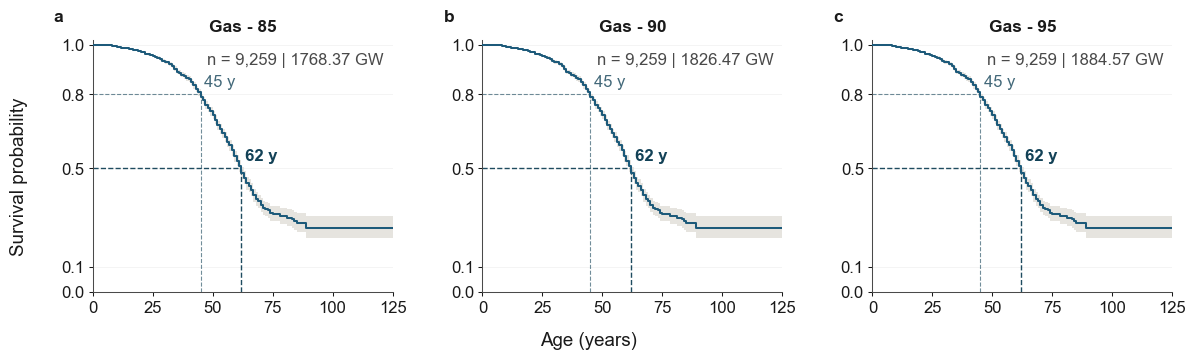

In [5]:
# ---
# Figure: three sensitivity cases in one row
# ---

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(
        11.8,
        3.65,
    ),
    sharex=True,
    sharey=True,
)

fig.patch.set_facecolor(
    COLOR_BACKGROUND
)

for panel_index, (
    ax,
    sheet_name,
) in enumerate(
    zip(
        axes,
        sheet_names,
    )
):
    ax.set_facecolor(
        COLOR_BACKGROUND
    )

    plot_km_panel(
        ax=ax,
        sheet_name=sheet_name,
        panel_label=chr(
            97 + panel_index
        ),
    )


# ---
# Global labels
# ---

fig.supylabel(
    "Survival probability",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    x=0.010,
    color=TEXT_COLOUR,
)

fig.supxlabel(
    "Age (years)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    y=0.025,
    color=TEXT_COLOUR,
)


# ---
# Layout
# ---

fig.subplots_adjust(
    left=0.080,
    right=0.995,
    bottom=0.185,
    top=0.875,
    wspace=0.30,
)


# ---
# Save
# ---

plt.savefig(
    "figures/SI/figure-9.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    "figures/SI/figure-9.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.show()